# **Préparation de Données : Adult Census Income**

### **Objectif**
Appliquer les étapes de préparation de données : nettoyage, transformation, sélection des caractéristiques.

### **Dataset utilisé**
Adult (Census Income) : 32 561 lignes, 15 colonnes. Cible : `income` (>50K ou <=50K).

### **ODS 1**
| Utilisateur visé | Objectif métier | Objectif Data Science |
|---|---|---|
| Une personne qui s'informe sur la valeur de son profil | Estimer ses chances d'atteindre un revenu > 50 000 $ | Classification binaire de `income` |

> Les caractéristiques ne sont pas choisies à l'avance : on garde toutes les colonnes jusqu'à la Partie 3, où la sélection se fait après analyse.

**Importer les bibliothèques nécessaires**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler

**Charger le dataset**

> Le fichier n'a pas d'en-tête : on nomme les colonnes. `skipinitialspace=True` enlève les espaces après les virgules.

In [ ]:
colonnes = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status',
            'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss',
            'hours_per_week', 'native_country', 'income']

df = pd.read_csv("adult.data.csv", header=None, names=colonnes, skipinitialspace=True)
print(df.shape)

(32561, 15)


**Exploration et aperçu des données**

`df.columns`

In [ ]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income'],
      dtype='object')

`df.head()`

In [ ]:
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


`df.tail()`

In [ ]:
df.tail()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
32560,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


`df.describe()`

In [ ]:
df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


`df.info()`

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


# **Partie 1 : Nettoyage de données**

### **Gestion des doublons**

1- Détection des doublons

In [ ]:
doublons = df[df.duplicated(keep=False)].sort_values(list(df.columns))
print(len(doublons))
doublons.head(10)

47


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
17673,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
18698,19,Private,97261,HS-grad,9,Never-married,Farming-fishing,Not-in-family,White,Male,0,0,40,United-States,<=50K
6990,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
21318,19,Private,138153,Some-college,10,Never-married,Adm-clerical,Own-child,White,Female,0,0,10,United-States,<=50K
15189,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K
21490,19,Private,146679,Some-college,10,Never-married,Exec-managerial,Own-child,Black,Male,0,0,30,United-States,<=50K
3917,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
31993,19,Private,251579,Some-college,10,Never-married,Other-service,Own-child,White,Male,0,0,14,United-States,<=50K
5805,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K
11631,20,Private,107658,Some-college,10,Never-married,Tech-support,Not-in-family,White,Female,0,0,10,United-States,<=50K


2- Décision sur les doublons

> On garde les 24 doublons (24 lignes sur 32 561, impact négligeable). Pour les supprimer : `df.drop_duplicates(inplace=True)`.

In [ ]:
# Décision : on conserve les doublons (aucune suppression)

3- Nombre de doublons restants

In [ ]:
print("Nombre de doublons:", df.duplicated().sum())

Nombre de doublons: 24


## **Gestion des valeurs manquantes**

> Dans ce dataset, les manquants sont codés `?`.

In [ ]:
print("Valeurs manquantes (codées '?') :")
print((df == '?').sum())

Valeurs manquantes (codées '?') :
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64


In [ ]:
manquant = (df['workclass'] == '?')
print(df.groupby(manquant)['income'].value_counts(normalize=True))

workclass  income
False      <=50K     0.751017
           >50K      0.248983
True       <=50K     0.895969
           >50K      0.104031
Name: proportion, dtype: float64


In [ ]:
df = df.replace('?', np.nan)
print(df.isna().sum()[lambda s: s > 0])

# Décision : on garde les lignes et on crée une catégorie 'Unknown'
# (les manquants ont 10,4 % de >50K contre 24,9 % : les supprimer déformerait l'échantillon)
for col in ['workclass', 'occupation', 'native_country']:
    df[col] = df[col].fillna('Unknown')
print(df.isna().sum().sum())   # doit afficher 0

**Visualisation des données**

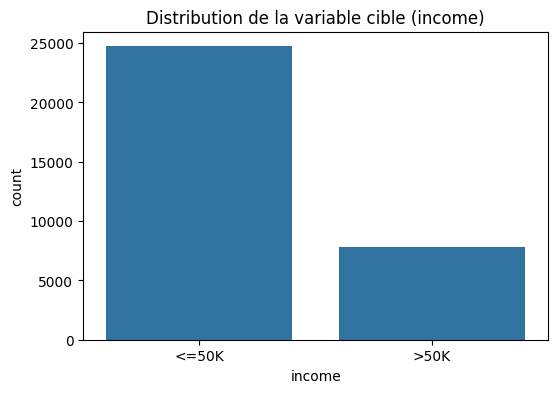

In [ ]:
# Distribution de la variable cible 'income'
plt.figure(figsize=(6, 4))
sns.countplot(x='income', data=df)
plt.title("Distribution de la variable cible (income)")
plt.show()

# **Partie 2 : Transformation de données**

**Encodage des variables catégorielles**

In [ ]:
# Identification des colonnes catégorielles
cat_cols = df.select_dtypes(include=['object']).columns
print("Variables catégorielles :", list(cat_cols))

# Encodage avec LabelEncoder pour les colonnes catégorielles
le = LabelEncoder()
for col in cat_cols:
    if col != 'income':
        df[col] = le.fit_transform(df[col])

Variables catégorielles : ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


**Encodage de la variable cible (`income`)**

In [ ]:
df['income'] = df['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)
print(df['income'].value_counts())

income
0    24720
1     7841
Name: count, dtype: int64


**Normalisation**

In [ ]:
num_cols = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
display(df[num_cols].head())

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
0,0.030671,-1.063611,1.134739,0.148453,-0.21666,-0.035429
1,0.837109,-1.008707,1.134739,-0.145920,-0.21666,-2.222153
2,-0.042642,0.245079,-0.420060,-0.145920,-0.21666,-0.035429
3,1.057047,0.425801,-1.197459,-0.145920,-0.21666,-0.035429
4,-0.775768,1.408176,1.134739,-0.145920,-0.21666,-0.035429


# **Partie 3 : Sélection des caractéristiques**

Règle de sélection : on garde une variable si elle est (a) liée à la cible, (b) non redondante avec une autre, (c) cohérente avec l'ODS (saisissable et actionnable par l'utilisateur).

**Matrice de corrélation**

> Attention : sur des catégories encodées avec `LabelEncoder`, la corrélation n'a pas de sens. Pour les variables catégorielles, comparer plutôt le taux de >50K par catégorie.

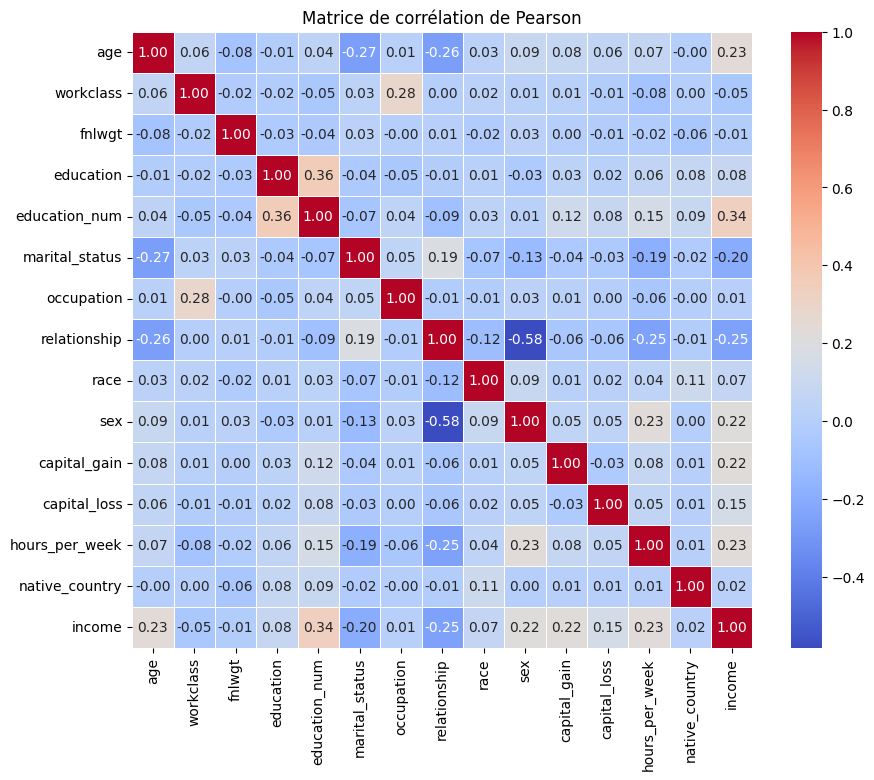

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title("Matrice de corrélation de Pearson")
plt.show()

In [ ]:
print(df.corr()['income'].abs().sort_values(ascending=False))

**Sélectionner les caractéristiques**

On applique la règle : (a) liée à la cible, (b) non redondante, (c) cohérente avec l'ODS.

- (a) Avec un seuil de 0,1, 8 variables passent : `education_num`, `relationship`, `age`, `hours_per_week`, `capital_gain`, `sex`, `marital_status`, `capital_loss`.
- (c) On écarte `capital_gain` et `capital_loss` (conséquences de la richesse), `sex` (critère sensible) et `relationship` / `marital_status` (proches de `sex`, non actionnables par l'utilisateur).
- Il reste `education_num`, `age`, `hours_per_week`, les 3 variables de l'ODS.

> Limite : la corrélation sur des catégories encodées avec `LabelEncoder` n'est pas fiable (ordre alphabétique), donc `workclass` et `occupation` sont peut-être sous-estimées.

In [ ]:
features_selectionnees = ['age', 'education_num', 'hours_per_week']

**Créer un DataFrame avec les caractéristiques sélectionnées**

In [ ]:
df_final = df[features_selectionnees + ['income']].copy()
X = df_final[features_selectionnees]
y = df_final['income']
display(df_final.head())

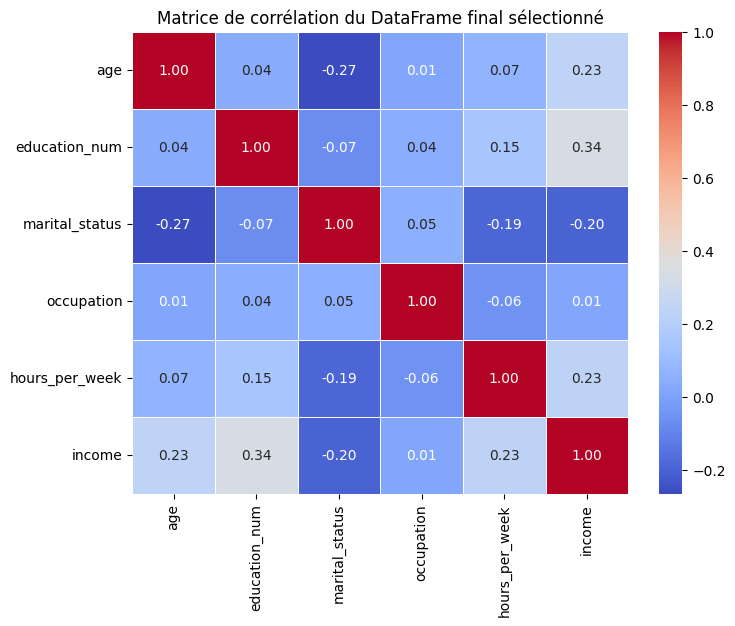

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_final.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title("Matrice de corrélation du DataFrame final sélectionné")
plt.show()

# **Partie 4 : Modélisation**

### **Rappel de l'ODS 1**
| Objectif métier | Objectif Data Science |
|---|---|
| Estimer les chances d'une personne d'atteindre un revenu > 50 000 $ | Classification binaire de `income` (1 = >50K, 0 = <=50K) à partir de `age`, `education_num`, `hours_per_week` |

### **Démarche**
1. Séparer les données en **train (80 %)** et **test (20 %)** avec `train_test_split(X, y, test_size=0.2, random_state=42)`, comme dans les TP. `random_state=42` rend le découpage reproductible.
2. Calculer une **baseline** (toujours prédire la classe majoritaire) : tout modèle doit la battre.
3. Entraîner une **régression logistique** (modèle simple, interprétable, donne une probabilité = les « chances » de l'ODS).
4. Entraîner un **XGBoost** (méthode du TP XGBoost), d'abord avec des hyperparamètres par défaut raisonnables, puis optimisé avec `RandomizedSearchCV`.

> Limite à connaître : la normalisation (`StandardScaler`) a été ajustée sur tout le dataset avant le découpage train/test (fuite d'information légère). La version rigoureuse consiste à découper d'abord puis à utiliser un `Pipeline`. L'effet est négligeable ici, et les arbres (XGBoost) ne dépendent pas de l'échelle.

**Importer les bibliothèques de modélisation**

In [ ]:
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_curve)
from xgboost import XGBClassifier

**Séparation train / test**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train :", X_train.shape, " Test :", X_test.shape)
print("Part de >50K dans le train :", round(y_train.mean(), 3))
print("Part de >50K dans le test  :", round(y_test.mean(), 3))

**Baseline (classe majoritaire)**

> Le jeu est déséquilibré (environ 76 % de <=50K). Un « modèle » qui répond toujours « <=50K » a déjà environ 76 % d'accuracy : il suffit de calculer la part de <=50K dans le test, sans aucun algorithme. C'est le seuil à dépasser.

In [ ]:
# Baseline : prédire toujours la classe majoritaire (<=50K), sans aucun modèle
accuracy_baseline = 1 - y_test.mean()
print("Accuracy baseline :", round(accuracy_baseline, 3))

**Modèle 1 : régression logistique**

In [ ]:
logreg = LogisticRegression(max_iter=1000, random_state=42)
logreg.fit(X_train, y_train)
print("Entraînement terminé. Coefficients :", dict(zip(X.columns, logreg.coef_[0].round(3))))

**Modèle 2 : XGBoost (hyperparamètres de départ)**

Mêmes hyperparamètres que dans le TP XGBoost : `learning_rate=0.1`, `max_depth=3`, `n_estimators=100`, `subsample=0.8`, `colsample_bytree=0.8`.

In [ ]:
xgb_base = XGBClassifier(
    learning_rate=0.1, max_depth=3, n_estimators=100,
    subsample=0.8, colsample_bytree=0.8,
    objective="binary:logistic", eval_metric="logloss", random_state=42)
xgb_base.fit(X_train, y_train)
print("Entraînement terminé.")

**Modèle 3 : XGBoost optimisé (`RandomizedSearchCV`)**

On utilise `RandomizedSearchCV` plutôt que `GridSearchCV` (beaucoup plus rapide, voir le TP XGBoost). Le score optimisé est l'**AUC** (`roc_auc`) et non l'accuracy, car le jeu est déséquilibré. La recherche se fait **uniquement sur le train** (validation croisée), le test reste intact.

In [ ]:
param_dist = {
    'learning_rate': [0.3, 0.1, 0.05, 0.01],
    'max_depth': [2, 3, 4, 5, 7],
    'n_estimators': [100, 200, 300],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 0.5, 1],
    'reg_alpha': [0, 1, 10],
    'reg_lambda': [1, 5, 10]
}

random_search = RandomizedSearchCV(
    XGBClassifier(objective="binary:logistic", eval_metric="logloss", random_state=42),
    param_distributions=param_dist,
    n_iter=20, scoring="roc_auc", cv=3, n_jobs=-1, random_state=42)

random_search.fit(X_train, y_train)

print("Meilleurs hyperparamètres :", random_search.best_params_)
print("Meilleur AUC (validation croisée) :", round(random_search.best_score_, 4))

xgb_best = random_search.best_estimator_

# **Partie 5 : Évaluation**

### **Pourquoi pas seulement l'accuracy ?**
Avec 24 % de >50K, l'accuracy seule est trompeuse (la baseline fait déjà ~76 %). On regarde donc aussi :

| Métrique | Question à laquelle elle répond |
|---|---|
| **Précision** | Parmi les personnes prédites >50K, combien le sont vraiment ? |
| **Rappel** (recall) | Parmi les vraies personnes >50K, combien le modèle en retrouve-t-il ? |
| **F1** | Compromis entre précision et rappel |
| **AUC-ROC** | Capacité à classer une personne >50K au-dessus d'une personne <=50K (0,5 = hasard, 1 = parfait), indépendante du seuil |

Toutes les métriques sont calculées sur le **jeu de test**, jamais vu pendant l'entraînement.

**Tableau comparatif des modèles**

In [ ]:
modeles = {
    "Régression logistique": logreg,
    "XGBoost (départ)": xgb_base,
    "XGBoost (optimisé)": xgb_best,
}

def evaluer(model):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Précision": precision_score(y_test, y_pred, zero_division=0),
        "Rappel": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_proba),
    }

resultats = pd.DataFrame({nom: evaluer(m) for nom, m in modeles.items()}).T.round(3)
display(resultats)

**Matrices de confusion**

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, nom in zip(axes, ["Régression logistique", "XGBoost (départ)", "XGBoost (optimisé)"]):
    ConfusionMatrixDisplay.from_estimator(
        modeles[nom], X_test, y_test, display_labels=["<=50K", ">50K"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

> Lecture : en bas à gauche, les **faux négatifs** (personnes >50K que le modèle rate) ; en haut à droite, les **faux positifs**. Avec peu de variables, le modèle rate typiquement beaucoup de >50K : le rappel est le point faible.

**Rapport de classification du meilleur modèle**

In [ ]:
print(classification_report(y_test, xgb_best.predict(X_test), target_names=["<=50K", ">50K"]))

**Courbes ROC**

In [ ]:
plt.figure(figsize=(7, 6))
for nom, m in modeles.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{nom} (AUC = {roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label="Hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs (rappel)")
plt.title("Courbes ROC")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

**Stabilité : validation croisée (5 plis stratifiés) sur le train**

Un seul découpage train/test peut être chanceux ou malchanceux. On vérifie que les scores restent proches d'un pli à l'autre (écart-type faible = modèle stable).

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lignes = {}
for nom in ["Régression logistique", "XGBoost (optimisé)"]:
    s = cross_validate(modeles[nom], X_train, y_train, cv=cv,
                       scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    lignes[nom] = {
        "Accuracy": f"{s['test_accuracy'].mean():.3f} ± {s['test_accuracy'].std():.3f}",
        "F1": f"{s['test_f1'].mean():.3f} ± {s['test_f1'].std():.3f}",
        "AUC": f"{s['test_roc_auc'].mean():.3f} ± {s['test_roc_auc'].std():.3f}",
    }
display(pd.DataFrame(lignes).T)

**Choix du seuil de décision**

Par défaut, une personne est classée >50K si sa probabilité dépasse 0,5. Comme les >50K sont minoritaires, ce seuil est souvent trop strict : baisser le seuil augmente le rappel au prix de la précision. Le bon seuil dépend de l'objectif métier : ici, informer l'utilisateur sur ses chances, donc la **probabilité elle-même** est plus utile que la classe.

In [ ]:
proba_best = xgb_best.predict_proba(X_test)[:, 1]

seuils = [0.2, 0.3, 0.4, 0.5, 0.6]
lignes = []
for s in seuils:
    y_s = (proba_best >= s).astype(int)
    lignes.append({"Seuil": s,
                   "Précision": precision_score(y_test, y_s, zero_division=0),
                   "Rappel": recall_score(y_test, y_s),
                   "F1": f1_score(y_test, y_s)})
display(pd.DataFrame(lignes).round(3).set_index("Seuil"))

**Importance des variables**

In [ ]:
importances = pd.DataFrame({
    "Variable": X.columns,
    "Coef. régression logistique": logreg.coef_[0],
    "Odds ratio (exp(coef))": np.exp(logreg.coef_[0]),
    "Importance XGBoost": xgb_best.feature_importances_,
}).set_index("Variable").round(3)
display(importances)

fig, ax = plt.subplots(figsize=(7, 3.5))
importances["Importance XGBoost"].sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Importance des variables (XGBoost)")
plt.tight_layout()
plt.show()

> Lecture : les variables ayant été normalisées, les coefficients de la régression logistique sont comparables entre eux. Un odds ratio > 1 signifie que la variable augmente les chances d'être >50K (à autres variables égales).

**Quel est le coût de la sélection des caractéristiques ?**

On compare XGBoost avec les **3 variables retenues** et avec **toutes les variables** (même découpage grâce à `random_state=42`). L'écart montre ce qu'on sacrifie en excluant `sex`, `marital_status`, `capital_gain`, etc. pour rester cohérent avec l'ODS.

In [ ]:
X_all = df.drop(columns='income')
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_all, y, test_size=0.2, random_state=42)

xgb_all = XGBClassifier(**xgb_best.get_params())
xgb_all.fit(Xa_train, ya_train)

comparaison = pd.DataFrame({
    "3 variables (ODS)": {
        "Accuracy": accuracy_score(y_test, xgb_best.predict(X_test)),
        "F1": f1_score(y_test, xgb_best.predict(X_test)),
        "AUC": roc_auc_score(y_test, xgb_best.predict_proba(X_test)[:, 1])},
    "Toutes les variables": {
        "Accuracy": accuracy_score(ya_test, xgb_all.predict(Xa_test)),
        "F1": f1_score(ya_test, xgb_all.predict(Xa_test)),
        "AUC": roc_auc_score(ya_test, xgb_all.predict_proba(Xa_test)[:, 1])},
}).T.round(3)
display(comparaison)

### **Conclusion**

- **Baseline** : environ 76 % d'accuracy sans rien apprendre. Un modèle n'est utile que s'il fait nettement mieux **en F1 et en AUC**, pas seulement en accuracy.
- **Modèles** : comparer régression logistique et XGBoost sur le tableau ci-dessus. Si l'écart est faible, privilégier la régression logistique (plus simple, interprétable, probabilités bien calibrées). Sinon retenir XGBoost.
- **Point faible attendu** : un rappel modeste sur la classe >50K avec seulement 3 variables ; on peut l'améliorer en baissant le seuil de décision.
- **Compromis assumé** : exclure `sex`, `marital_status`, `relationship`, `capital_gain`, `capital_loss` coûte un peu de performance (voir la comparaison finale) mais rend l'outil cohérent avec l'ODS (variables que l'utilisateur peut saisir et faire évoluer) et évite d'utiliser un critère sensible.
- **Pistes d'amélioration** : ajouter `workclass` et `occupation` avec un encodage one-hot (plutôt que `LabelEncoder`), gérer le déséquilibre (`scale_pos_weight`), utiliser un `Pipeline` pour éviter la fuite lors de la normalisation.

# **Partie 6 : Comparaison de 5 modèles**

On compare 5 modèles sur les **mêmes données** (mêmes `X_train` / `X_test`). Voici ce qu'il faut savoir sur chacun.

### **1. Régression logistique**
- **Principe** : calcule une somme pondérée des variables, `z = b0 + b1·age + b2·education_num + b3·hours_per_week`, puis la transforme en probabilité avec la fonction sigmoïde `p = 1 / (1 + e^(-z))`. Si `p ≥ 0,5` : classe >50K.
- **Points forts** : simple, très rapide, **interprétable** (chaque coefficient dit si la variable augmente ou diminue les chances ; `exp(coef)` = odds ratio), probabilités bien calibrées.
- **Limites** : frontière de décision **linéaire**, ne capte pas les interactions ou effets non linéaires (ex. l'effet de l'âge qui monte puis redescend).
- **Réglages clés** : `C` (régularisation), `max_iter`. Nécessite des variables normalisées (déjà fait).

### **2. Arbre de décision**
- **Principe** : pose une suite de questions oui/non (« education_num > 0,5 ? », « age > 30 ? »…) qui découpent les données en groupes de plus en plus purs. Chaque feuille donne la classe majoritaire.
- **Points forts** : règles **lisibles** et visualisables, capte les non-linéarités et les interactions, pas besoin de normalisation.
- **Limites** : **sur-apprentissage** si l'arbre est trop profond (il apprend le bruit), instable (un petit changement des données change l'arbre).
- **Réglages clés** : `max_depth`, `min_samples_leaf` (limitent la complexité).

### **3. Random Forest (forêt aléatoire)**
- **Principe** : construit de nombreux arbres, chacun sur un **échantillon bootstrap** des données et un sous-ensemble aléatoire de variables, puis fait **voter** les arbres (*bagging*). La moyenne réduit la variance.
- **Points forts** : bien plus stable et performant qu'un arbre seul, robuste, peu de réglages, donne l'importance des variables.
- **Limites** : moins interprétable (centaines d'arbres), plus lent, ne corrige pas les erreurs systématiques.
- **Réglages clés** : `n_estimators`, `max_depth`, `min_samples_leaf`.

### **4. XGBoost (optimisé)**
- **Principe** : *boosting* : les arbres sont construits **l'un après l'autre**, chacun corrigeant les erreurs du précédent (descente de gradient sur la perte), avec régularisation intégrée.
- **Points forts** : souvent le plus performant sur données tabulaires, gère le déséquilibre (`scale_pos_weight`), régularisation (`reg_alpha`, `reg_lambda`, `gamma`).
- **Limites** : beaucoup d'hyperparamètres à régler (d'où `RandomizedSearchCV`), risque de sur-apprentissage si mal réglé, moins interprétable (SHAP en complément).
- **Réglages clés** : `learning_rate`, `max_depth`, `n_estimators`, `subsample`, `colsample_bytree`.

### **5. KNN (K plus proches voisins)**
- **Principe** : pour une nouvelle personne, cherche les **k personnes les plus proches** (distance euclidienne) dans le train et prend la classe majoritaire. Il n'y a pas d'entraînement : il mémorise les données.
- **Points forts** : très intuitif, aucune hypothèse sur la forme des données.
- **Limites** : **sensible à l'échelle** des variables (d'où la normalisation), lent en prédiction sur gros jeux de données, souffre quand il y a beaucoup de variables, mauvais avec des catégories encodées en nombres.
- **Réglage clé** : `n_neighbors` (k petit = sur-apprentissage, k grand = sous-apprentissage).

### **Méthode de comparaison**
Le choix se fait par **validation croisée sur le train** (AUC). Le **test** ne sert qu'à confirmer, pour ne pas choisir le modèle en regardant le test.

In [ ]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

modeles5 = {
    "Régression logistique": LogisticRegression(max_iter=1000, random_state=42),
    "Arbre de décision": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "XGBoost optimisé": xgb_best,
    "KNN (k=25)": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
}

**Validation croisée (5 plis) sur le train**

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
lignes, auc_plis = [], {}
for nom, m in modeles5.items():
    t0 = time.time()
    s = cross_validate(m, X_train, y_train, cv=cv,
                       scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    auc_plis[nom] = s["test_roc_auc"]
    lignes.append({
        "Modèle": nom,
        "Accuracy (CV)": s["test_accuracy"].mean(),
        "F1 (CV)": s["test_f1"].mean(),
        "AUC (CV)": s["test_roc_auc"].mean(),
        "Écart-type AUC": s["test_roc_auc"].std(),
        "Temps (s)": time.time() - t0,
    })
cv_resultats = pd.DataFrame(lignes).set_index("Modèle").sort_values("AUC (CV)", ascending=False).round(3)
display(cv_resultats)

**Confirmation sur le jeu de test + détection du sur-apprentissage (AUC train vs test)**

In [ ]:
lignes, probas = {}, {}
for nom, m in modeles5.items():
    m_fit = m if nom == "XGBoost optimisé" else m.fit(X_train, y_train)
    y_pred = m_fit.predict(X_test)
    probas[nom] = m_fit.predict_proba(X_test)[:, 1]
    auc_train = roc_auc_score(y_train, m_fit.predict_proba(X_train)[:, 1])
    auc_test = roc_auc_score(y_test, probas[nom])
    lignes[nom] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Précision": precision_score(y_test, y_pred, zero_division=0),
        "Rappel": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC test": auc_test,
        "AUC train": auc_train,
        "Écart train-test": auc_train - auc_test,
    }
test_resultats = pd.DataFrame(lignes).T.sort_values("AUC test", ascending=False).round(3)
display(test_resultats)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

test_resultats["AUC test"].sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_xlim(0.5, test_resultats["AUC test"].max() + 0.03)
axes[0].set_title("AUC sur le jeu de test")

for nom, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{nom} ({roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("Courbes ROC")
axes[1].set_xlabel("Taux de faux positifs")
axes[1].set_ylabel("Rappel")
axes[1].legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

# **Partie 7 : Notre choix est-il bon ?**

On vérifie 4 points avant de valider le modèle retenu :

1. **Y a-t-il vraiment un gagnant ?** Si l'écart d'AUC entre le meilleur et les autres est plus petit que l'écart-type de la validation croisée, ils sont **statistiquement équivalents** : on prend alors le plus simple.
2. **Sur-apprentissage ?** Un écart AUC train − test élevé (> 0,03 à 0,05) signale que le modèle a appris le bruit.
3. **Le modèle bat-il la baseline ?** Il doit nettement dépasser 76 % d'accuracy et surtout 0,5 d'AUC.
4. **Le choix des 3 variables est-il bon ?** On refait tourner les 5 modèles avec toutes les variables.

In [ ]:
# Points 1 à 3 : verdict automatique
simplicite = ["Régression logistique", "Arbre de décision", "KNN (k=25)", "Random Forest", "XGBoost optimisé"]

meilleur = cv_resultats["AUC (CV)"].idxmax()
auc_max = cv_resultats.loc[meilleur, "AUC (CV)"]
marge = cv_resultats.loc[meilleur, "Écart-type AUC"]

equivalents = [m for m in cv_resultats.index if auc_max - cv_resultats.loc[m, "AUC (CV)"] <= marge]
choix = min(equivalents, key=simplicite.index)

print("1) Meilleur AUC en validation croisée :", meilleur, f"({auc_max:.3f})")
print("   Modèles équivalents (écart <= 1 écart-type = %.3f) :" % marge, equivalents)
print("   -> Modèle retenu (le plus simple parmi les équivalents) :", choix)

gap = test_resultats.loc[choix, "Écart train-test"]
print(f"\n2) Écart AUC train-test de {choix} : {gap:.3f} ->",
      "pas de sur-apprentissage notable" if gap < 0.03 else "attention, sur-apprentissage possible")

acc = test_resultats.loc[choix, "Accuracy"]
auc = test_resultats.loc[choix, "AUC test"]
print(f"\n3) Accuracy test = {acc:.3f} (baseline = {1 - y_test.mean():.3f}), AUC test = {auc:.3f} (hasard = 0.5)")

In [ ]:
# Point 4 : 3 variables (ODS) vs toutes les variables, pour les 5 modèles
lignes = {}
for nom, m in modeles5.items():
    m3 = m
    m_all = XGBClassifier(**xgb_best.get_params()) if nom == "XGBoost optimisé" else type(m)(**m.get_params())
    m_all.fit(Xa_train, ya_train)
    lignes[nom] = {
        "AUC (3 variables)": roc_auc_score(y_test, m3.predict_proba(X_test)[:, 1]),
        "AUC (toutes variables)": roc_auc_score(ya_test, m_all.predict_proba(Xa_test)[:, 1]),
    }
comp = pd.DataFrame(lignes).T
comp["Gain"] = comp["AUC (toutes variables)"] - comp["AUC (3 variables)"]
display(comp.round(3))

### **Comment conclure**

| Constat | Conclusion |
|---|---|
| Plusieurs modèles dans la marge d'un écart-type | Le choix de l'algorithme n'a **pas d'importance** : garder le plus simple (souvent la régression logistique), plus facile à expliquer et à défendre. |
| Un modèle d'ensemble (Random Forest, XGBoost) nettement devant | Retenir ce modèle, en vérifiant l'écart train-test. |
| Arbre ou KNN loin derrière | Normal : variance élevée (arbre) ou sensibilité au bruit (KNN). |
| Gain important avec toutes les variables | Les 3 variables limitent la performance. Ce choix est **cohérent avec l'ODS** (variables que l'utilisateur peut saisir, pas de variable sensible comme `sex`) mais il a un coût, à assumer et à expliquer. |
| Gain faible avec toutes les variables | La sélection est **un bon choix** : on garde presque toute la performance avec 3 variables seulement. |

> Remarque : KNN avec toutes les variables est peu fiable, car les catégories encodées par `LabelEncoder` (ex. `workclass` = 0…8) n'ont pas de notion de distance. Pour une comparaison rigoureuse, il faudrait un encodage one-hot.

**À retenir pour l'oral** : on ne choisit pas un modèle sur le test, on vérifie qu'il ne sur-apprend pas, on compare à une baseline, et on justifie le compromis entre performance et simplicité.